In [1]:
#Christian Yanez
#Question 1
#a. Forward Propagation
import numpy as np
import warnings
warnings.filterwarnings("default")
#provided code
x = np.array([0.7, 0.3, 0.5]).reshape(3, 1)
y = np.array([1]).reshape(1, 1)

weights = [
    np.array([[-1.0, -2.3, 1.7],
              [-0.8,  0.3, 1.4]]),
    np.array([[-2.0, -0.4]])
]

biases = [
    np.array([[ 1.6],
              [-0.6]]),
    np.array([[-0.5]])
]

#forward propagation function
def forward_prop(x, y, ws, bs):
    zs = [x]

    for i in range(len(ws)):
        a = np.dot(ws[i], zs[-1]) + bs[i]#before activation
        z = 1 / (1 + np.exp(-a))#this is the sigmoid activation function
        zs.append(z)

    E = 1/2 * (y - zs[-1])**2

    return zs, E

zs, E = forward_prop(x, y, weights, biases)
print(f'zs = {zs}')
print(f'E = {E}')

zs = [array([[0.7],
       [0.3],
       [0.5]]), array([[0.74269055],
       [0.40854102]]), array([[0.10444365]])]
E = [[0.40101059]]


In [2]:
#backward propagation

def back_prop(y, zs, weights, biases, eta):
    #delta equation taken from the lectures
    delta = (zs[-1] - y) * zs[-1] * (1 - zs[-1])
    #Loop has to go backwards. 
    for i in range(len(weights) - 1, -1, -1):

        dW = np.dot(delta, zs[i].T)
        db = delta

        old_w = weights[i].copy()
        #updating the weight and bias
        weights[i] = weights[i] - eta * dW
        biases[i] = biases[i] - eta * db
        #hidden layer checker
        if i > 0:
            delta = np.dot(old_w.T, delta) * zs[i] * (1 - zs[i])

    return weights, biases

eta = 3.0
weights, biases = back_prop(y, zs, weights, biases, eta)

print(f'weights = {weights}')
print(f'biases = {biases}')

weights = [array([[-1.06723274, -2.32881403,  1.65197662],
       [-0.81700229,  0.2927133 ,  1.38785551]]), array([[-1.81336331, -0.29733444]])]
biases = [array([[ 1.50395323],
       [-0.62428899]]), array([[-0.24870195]])]


In [3]:
x = np.array([5.2, -2.3, -1.7, 8.3]).reshape(4, 1)
y = np.array([0, 1]).reshape(2, 1)
eta = 5.0

weights = [
    np.array([[ 0.09, -0.68, -0.38, 0.93],
              [-0.37,  0.61,  0.45, 0.57],
              [-0.29, -0.76,  0.46, 0.01]]),
    np.array([[ 0.20, -0.20, 0.83],
              [ 0.35, -0.59, 0.36]])
]

biases = [
    np.array([[-0.53],
              [ 0.84],
              [-0.34]]),
    np.array([[-0.31],
              [ 0.36]])
]

zs, E = forward_prop(x, y, weights, biases)
print(f'zs = {zs}')
print(f'E = {E}')

weights, biases = back_prop(y, zs, weights, biases, eta)
print(f'weights = {weights}')
print(f'biases = {biases}')

zs = [array([[ 5.2],
       [-2.3],
       [-1.7],
       [ 8.3]]), array([[0.99994814],
       [0.81442149],
       [0.31023947]]), array([[0.4961511 ],
       [0.58447212]])]
E = [[0.12308296]
 [0.08633171]]
weights = [array([[ 0.09001418, -0.68000627, -0.38000463,  0.93002263],
       [-0.50649493,  0.67037276,  0.49462334,  0.35213309],
       [-0.660631  , -0.59606706,  0.58116783, -0.5815841 ]]), array([[-0.42011997, -0.70506522,  0.63760433],
       [ 0.8545586 , -0.17905532,  0.51654211]])]
biases = [array([[-0.52999727],
       [ 0.81375097],
       [-0.41127519]]), array([[-0.93015212],
       [ 0.86458477]])]


In [4]:
#Question 2 Training Data Process
#Train test split
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
DF = pd.read_csv('Hitters.csv')
train_set, test_set = train_test_split(DF, test_size=0.2, random_state=42)

#Exploratory Data Analysis (EDA)
#Explore distributions of key numerical and categorical variables.

numerical = train_set.select_dtypes(include='number').columns
categorical = train_set.select_dtypes(exclude='number').columns

print("Numerical variables:")
print(numerical)

print("\nCategorical variables:")
print(categorical)


Numerical variables:
Index(['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat',
       'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'PutOuts', 'Assists',
       'Errors', 'Salary'],
      dtype='object')

Categorical variables:
Index(['League', 'Division', 'NewLeague'], dtype='object')


In [5]:
#Identify missing values, outliers, and potential data quality issues.

print("\nThe amount of null values in each attribute \n",train_set.isnull().sum())



The amount of null values in each attribute 
 AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
Salary       45
NewLeague     0
dtype: int64


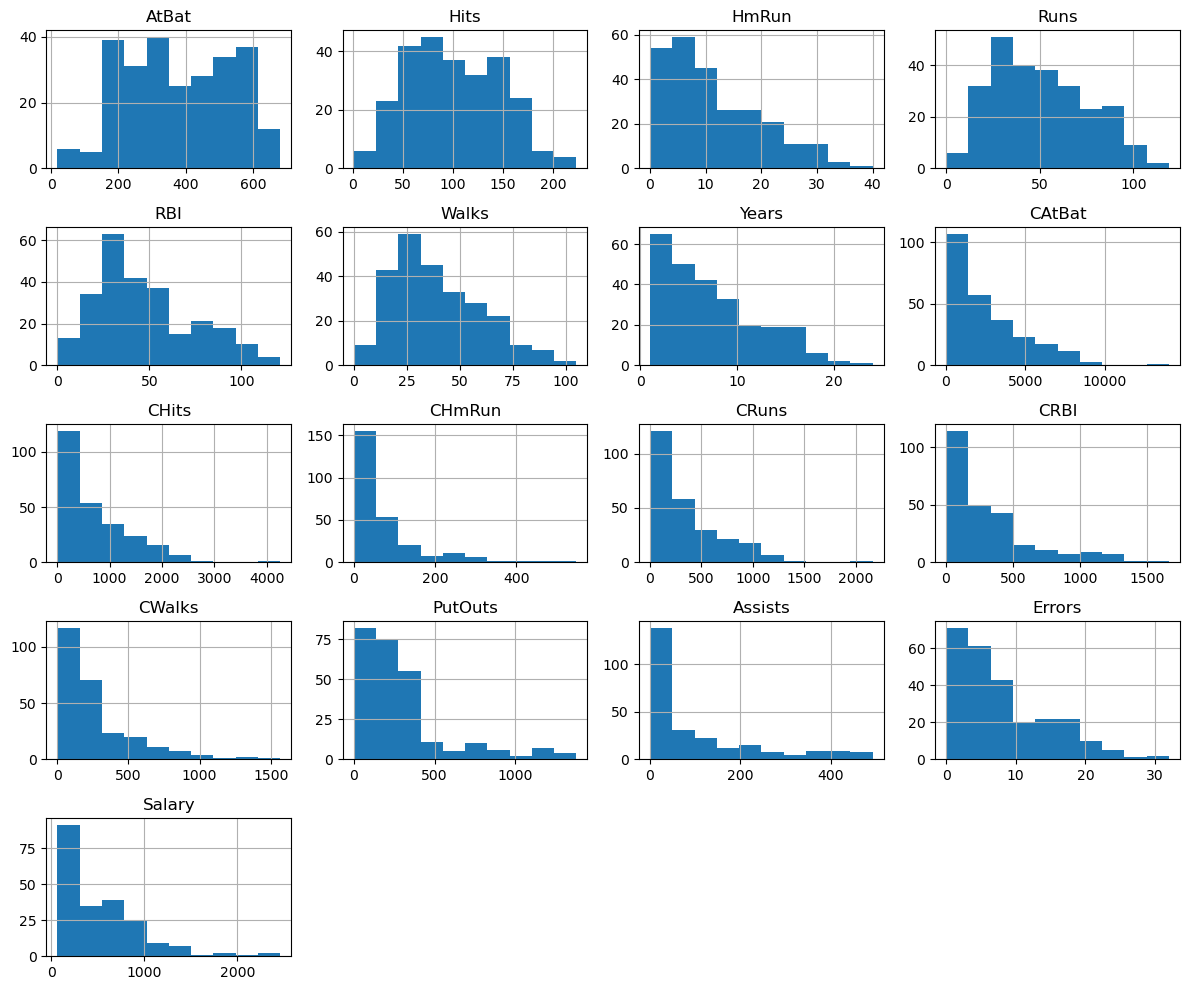

In [6]:
#Use appropriate plots (e.g., histograms, boxplots, scatterplots, correlation heatmaps) to support your discussion.

train_set[numerical].hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

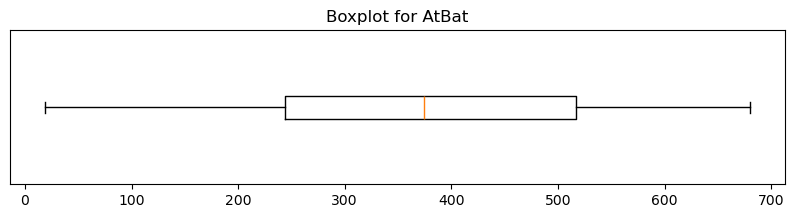

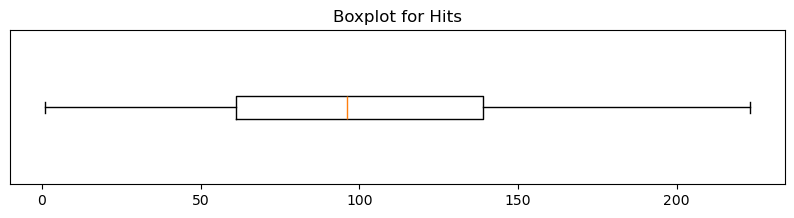

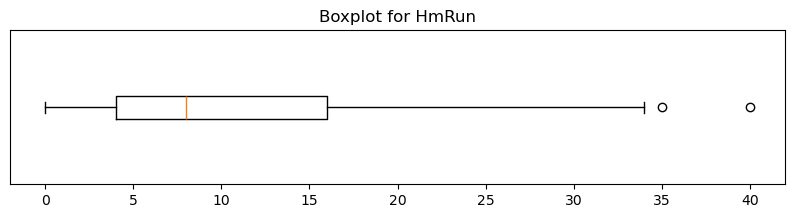

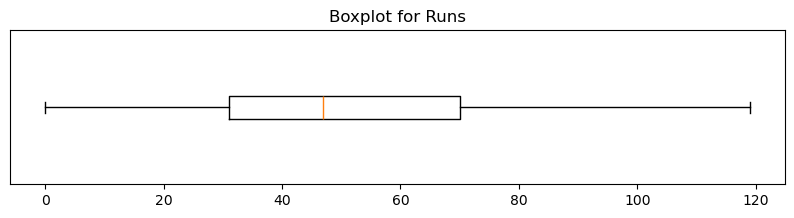

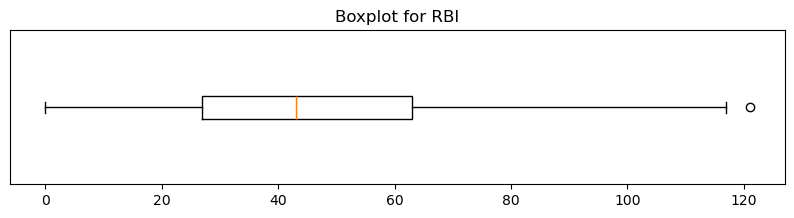

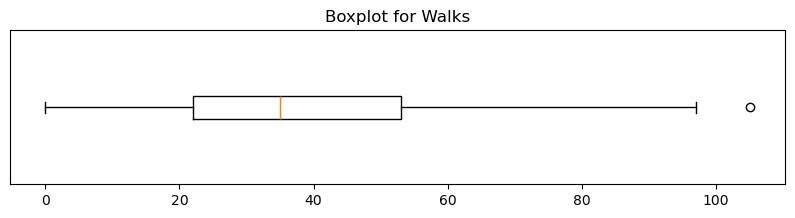

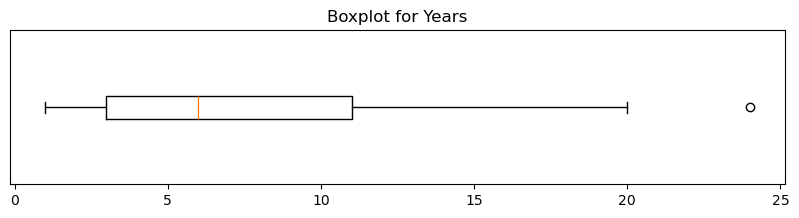

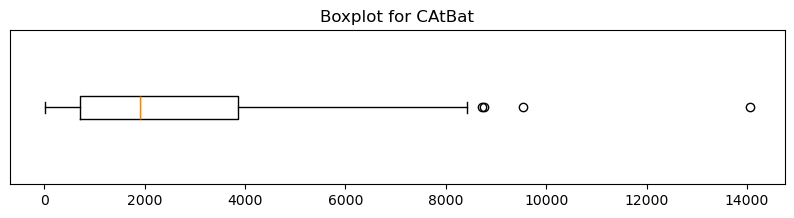

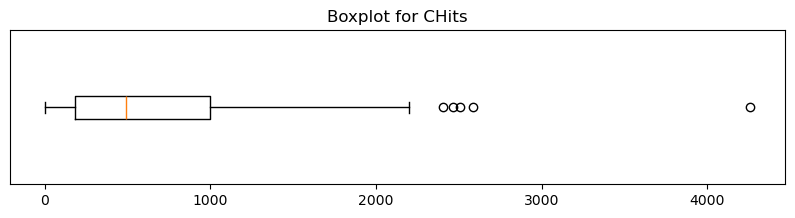

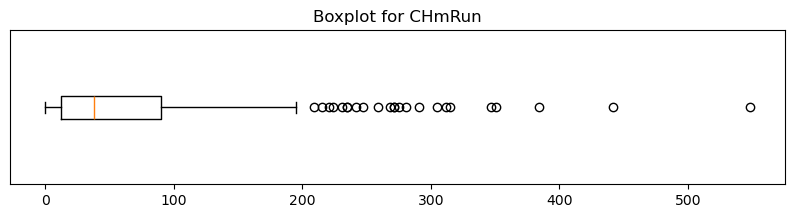

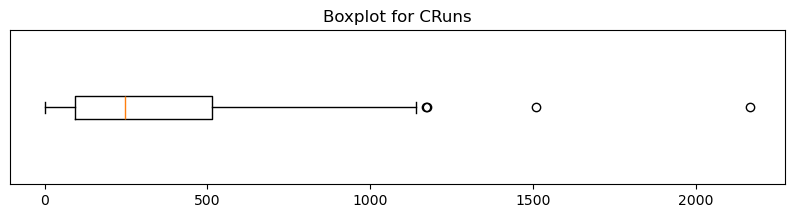

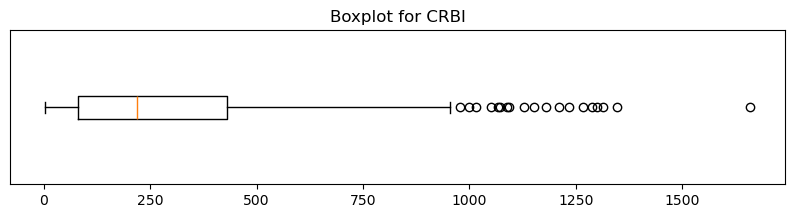

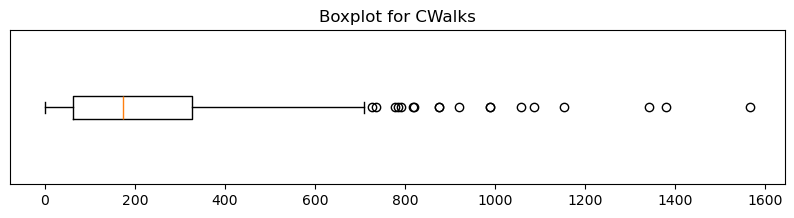

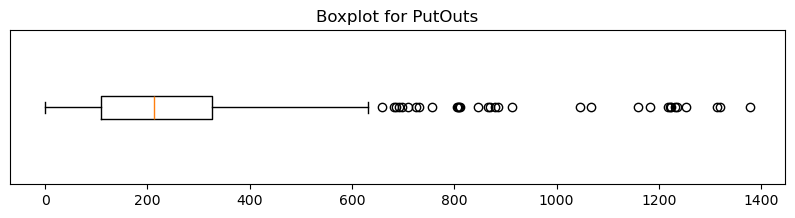

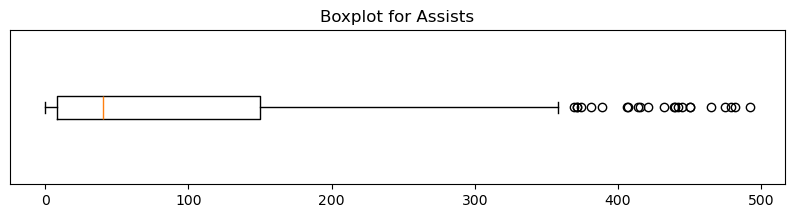

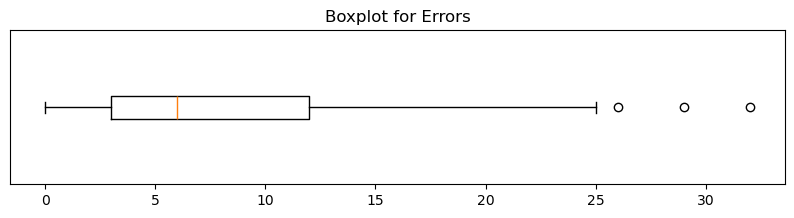

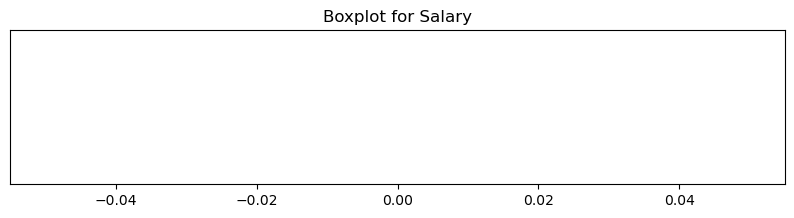

"\nOutliers can vary on if they are inaccuracy or just simply outliers that just exist. For example, there is one value at CAtBat at 14053.\nAn extreme outlier is completely not unreasonable, but it is important to keep in mind so the average isn't too skewed in the wrong\ndirection.\nBoxplot can get us a reasonable local maxima and minima, a median and a 25% and 75% percentile.\n"

In [7]:
for col in numerical:
    plt.figure(figsize=(10, 2))
    
    # Horizontal boxplot
    plt.boxplot(
        train_set[col],
        orientation='horizontal'
    )
    
    plt.title(f"Boxplot for {col}")
    plt.yticks([])
    plt.show()

"""
Outliers can vary on if they are inaccuracy or just simply outliers that just exist. For example, there is one value at CAtBat at 14053.
An extreme outlier is completely not unreasonable, but it is important to keep in mind so the average isn't too skewed in the wrong
direction.
Boxplot can get us a reasonable local maxima and minima, a median and a 25% and 75% percentile.
"""

In [8]:
#Feature reduction and engineering
"""
correlation = train_set[numerical].corr()

print(correlation)

The features that I am deciding to remove are any features that are too redundant and have very high correlation with other features it 
would be: CAtBat, CHits, CRuns, CRBI, and CWalks. This information appears to be very redundant. And I believe the similar values names
without the C at the front could cover more information and can be used to find ratios such as accuracy.

While the categorical variables are more 
for listing information such as any league transfers and division. They would be more independent of each other.
"""

reduced_features = [
    'AtBat',
    'Hits',
    'HmRun',
    'Runs',
    'RBI',
    'Walks',
    'Years',
    'CHmRun',
    'PutOuts',
    'Assists',
    'Errors',
    'League',
    'NewLeague',
    'Division',
    'Salary'
]
train_reduced = train_set[reduced_features]


In [9]:
#Apply transformations to test set
test_reduced = test_set[reduced_features]
print("These are the features in the reduced training data\n")
for feature in train_reduced.columns:
    print(feature)
print("\nThese are the features in the reduced test data:\n")
for feature in test_reduced.columns:
    print(feature)
#To show that both reduced training and test sets have the same columns

These are the features in the reduced training data

AtBat
Hits
HmRun
Runs
RBI
Walks
Years
CHmRun
PutOuts
Assists
Errors
League
NewLeague
Division
Salary

These are the features in the reduced test data:

AtBat
Hits
HmRun
Runs
RBI
Walks
Years
CHmRun
PutOuts
Assists
Errors
League
NewLeague
Division
Salary


In [ ]:
#Save Processed Data
#Which I have done by using the .to_csv function to save the new files on my device